In [2]:
import os
import pandas as pd
import numpy as np

from pyspark import SparkConf, SparkContext
from pyspark.sql import SparkSession, SQLContext

from pyspark.sql.types import *
import pyspark.sql.functions as F
from pyspark.sql.functions import udf, col

from pyspark.ml.regression import LinearRegression
from pyspark.mllib.evaluation import RegressionMetrics

from pyspark.ml.tuning import ParamGridBuilder, CrossValidator, CrossValidatorModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.evaluation import RegressionEvaluator

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Visualization
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [5]:
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_colwidth', 400)

In [6]:
print(pd.set_option)

In [7]:
from matplotlib import rcParams
sns.set(context='notebook', style='whitegrid', rc={'figure.figsize': (18,4)})
rcParams['figure.figsize'] = 18,4

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [8]:
# setting random seed for notebook reproducability
rnd_seed=23
np.random.seed=rnd_seed
np.random.set_state=rnd_seed

In [9]:
spark = SparkSession.builder.master("local[2]").appName("Linear-Regression-California-Housing").getOrCreate()

In [10]:
spark

In [11]:
sc = spark.sparkContext
sc

<SparkContext master=local[2] appName=Linear-Regression-California-Housing>

In [12]:
sqlContext = SQLContext(spark.sparkContext)
sqlContext

/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:112: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [13]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# 1. Charger les données California Housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# 2. Réorganiser les colonnes dans l'ordre exact de ton StructType Spark
df_spark = pd.DataFrame({
    'long': df['Longitude'],
    'lat': df['Latitude'],
    'medage': df['HouseAge'],
    'totrooms': df['AveRooms'],
    'totbdrms': df['AveBedrms'],
    'pop': df['Population'],
    'houshlds': df['AveOccup'],
    'medinc': df['MedInc'],
    'medhv': df['MedHouseVal']
})

# 3. Sauvegarder au format texte/CSV SANS en-tête (header=False)
# pour correspondre au fichier .data d'origine
df_spark.to_csv("cal_housing.data", header=False, index=False, sep=',')

print("Fichier cal_housing.data généré avec succès !")

Fichier cal_housing.data généré avec succès !


In [17]:
HOUSING_DATA = "cal_housing.data"

# Définition du schéma correspondant aux données générées
schema = StructType([
    StructField("long", DoubleType(), True),
    StructField("lat", DoubleType(), True),
    StructField("medage", DoubleType(), True),
    StructField("totrooms", DoubleType(), True),
    StructField("totbdrms", DoubleType(), True),
    StructField("pop", DoubleType(), True),
    StructField("houshlds", DoubleType(), True),
    StructField("medinc", DoubleType(), True),
    StructField("medhv", DoubleType(), True)
])

housing_df = spark.read.csv(path=HOUSING_DATA, schema=schema).cache()

In [18]:
# Inspect first five rows
housing_df.take(5)

[Row(long=-122.23, lat=37.88, medage=41.0, totrooms=6.984126984126984, totbdrms=1.0238095238095237, pop=322.0, houshlds=2.5555555555555554, medinc=8.3252, medhv=4.526),
 Row(long=-122.22, lat=37.86, medage=21.0, totrooms=6.238137082601054, totbdrms=0.9718804920913884, pop=2401.0, houshlds=2.109841827768014, medinc=8.3014, medhv=3.585),
 Row(long=-122.24, lat=37.85, medage=52.0, totrooms=8.288135593220339, totbdrms=1.073446327683616, pop=496.0, houshlds=2.8022598870056497, medinc=7.2574, medhv=3.521),
 Row(long=-122.25, lat=37.85, medage=52.0, totrooms=5.8173515981735155, totbdrms=1.0730593607305936, pop=558.0, houshlds=2.547945205479452, medinc=5.6431, medhv=3.413),
 Row(long=-122.25, lat=37.85, medage=52.0, totrooms=6.281853281853282, totbdrms=1.0810810810810811, pop=565.0, houshlds=2.1814671814671813, medinc=3.8462, medhv=3.422)]

In [19]:
# Show first five rows
housing_df.show(5)

+-------+-----+------+------------------+------------------+------+------------------+------+-----+
|   long|  lat|medage|          totrooms|          totbdrms|   pop|          houshlds|medinc|medhv|
+-------+-----+------+------------------+------------------+------+------------------+------+-----+
|-122.23|37.88|  41.0| 6.984126984126984|1.0238095238095237| 322.0|2.5555555555555554|8.3252|4.526|
|-122.22|37.86|  21.0| 6.238137082601054|0.9718804920913884|2401.0| 2.109841827768014|8.3014|3.585|
|-122.24|37.85|  52.0| 8.288135593220339| 1.073446327683616| 496.0|2.8022598870056497|7.2574|3.521|
|-122.25|37.85|  52.0|5.8173515981735155|1.0730593607305936| 558.0| 2.547945205479452|5.6431|3.413|
|-122.25|37.85|  52.0| 6.281853281853282|1.0810810810810811| 565.0|2.1814671814671813|3.8462|3.422|
+-------+-----+------+------------------+------------------+------+------------------+------+-----+
only showing top 5 rows


In [20]:
# show the dataframe columns
housing_df.columns

['long',
 'lat',
 'medage',
 'totrooms',
 'totbdrms',
 'pop',
 'houshlds',
 'medinc',
 'medhv']

In [21]:
# show the schema of the dataframe
housing_df.printSchema()

root
 |-- long: double (nullable = true)
 |-- lat: double (nullable = true)
 |-- medage: double (nullable = true)
 |-- totrooms: double (nullable = true)
 |-- totbdrms: double (nullable = true)
 |-- pop: double (nullable = true)
 |-- houshlds: double (nullable = true)
 |-- medinc: double (nullable = true)
 |-- medhv: double (nullable = true)



In [22]:
# run a sample selection
housing_df.select('pop','totbdrms').show(10)

+------+------------------+
|   pop|          totbdrms|
+------+------------------+
| 322.0|1.0238095238095237|
|2401.0|0.9718804920913884|
| 496.0| 1.073446327683616|
| 558.0|1.0730593607305936|
| 565.0|1.0810810810810811|
| 413.0|1.1036269430051813|
|1094.0|0.9513618677042801|
|1157.0| 1.061823802163833|
|1206.0|1.1176470588235294|
|1551.0|0.9901960784313726|
+------+------------------+
only showing top 10 rows


In [23]:
# group by housingmedianage and see the distribution
result_df = housing_df.groupBy("medage").count().sort("medage", ascending=False)

In [24]:
result_df.show(10)

+------+-----+
|medage|count|
+------+-----+
|  52.0| 1273|
|  51.0|   48|
|  50.0|  136|
|  49.0|  134|
|  48.0|  177|
|  47.0|  198|
|  46.0|  245|
|  45.0|  294|
|  44.0|  356|
|  43.0|  353|
+------+-----+
only showing top 10 rows


<Axes: xlabel='medage'>

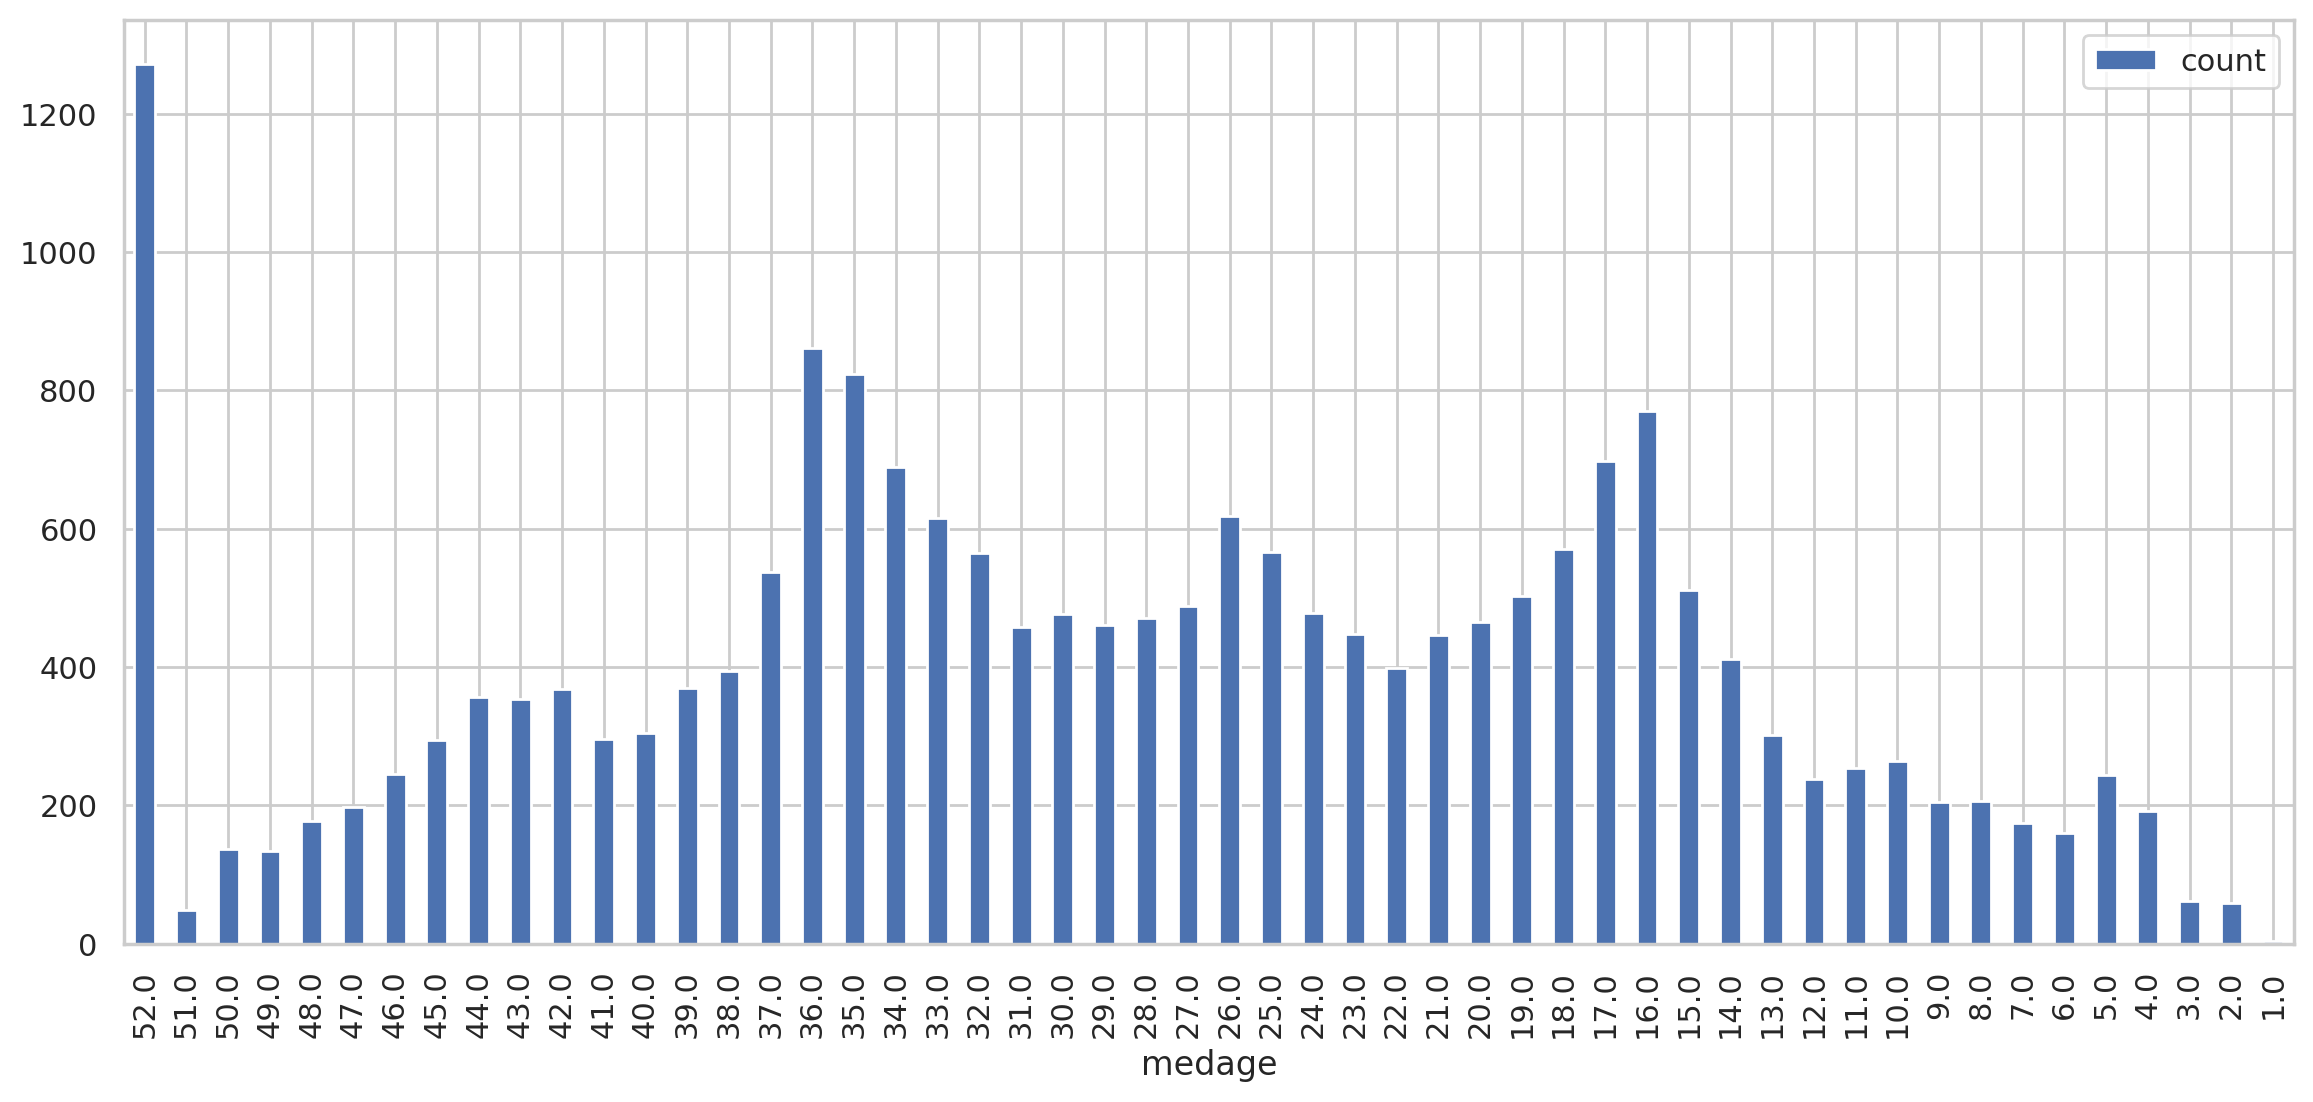

In [25]:
result_df.toPandas().plot.bar(x='medage',figsize=(14, 6))

In [26]:
(housing_df.describe().select(
                    "summary",
                    F.round("medage", 4).alias("medage"),
                    F.round("totrooms", 4).alias("totrooms"),
                    F.round("totbdrms", 4).alias("totbdrms"),
                    F.round("pop", 4).alias("pop"),
                    F.round("houshlds", 4).alias("houshlds"),
                    F.round("medinc", 4).alias("medinc"),
                    F.round("medhv", 4).alias("medhv"))
                    .show())

+-------+-------+--------+--------+---------+---------+-------+-------+
|summary| medage|totrooms|totbdrms|      pop| houshlds| medinc|  medhv|
+-------+-------+--------+--------+---------+---------+-------+-------+
|  count|20640.0| 20640.0| 20640.0|  20640.0|  20640.0|20640.0|20640.0|
|   mean|28.6395|   5.429|  1.0967|1425.4767|   3.0707| 3.8707| 2.0686|
| stddev|12.5856|  2.4742|  0.4739|1132.4621|   10.386| 1.8998|  1.154|
|    min|    1.0|  0.8462|  0.3333|      3.0|   0.6923| 0.4999|   0.15|
|    max|   52.0|141.9091| 34.0667|  35682.0|1243.3333|15.0001|    5.0|
+-------+-------+--------+--------+---------+---------+-------+-------+



In [27]:
# Adjust the values of `medianHouseValue`
housing_df = housing_df.withColumn("medhv", col("medhv")/100000)

In [28]:
# Show the first 2 lines of `df`
housing_df.show(20)

+-------+-----+------+------------------+------------------+------+------------------+------+--------------------+
|   long|  lat|medage|          totrooms|          totbdrms|   pop|          houshlds|medinc|               medhv|
+-------+-----+------+------------------+------------------+------+------------------+------+--------------------+
|-122.23|37.88|  41.0| 6.984126984126984|1.0238095238095237| 322.0|2.5555555555555554|8.3252|            4.526E-5|
|-122.22|37.86|  21.0| 6.238137082601054|0.9718804920913884|2401.0| 2.109841827768014|8.3014|            3.585E-5|
|-122.24|37.85|  52.0| 8.288135593220339| 1.073446327683616| 496.0|2.8022598870056497|7.2574|            3.521E-5|
|-122.25|37.85|  52.0|5.8173515981735155|1.0730593607305936| 558.0| 2.547945205479452|5.6431|            3.413E-5|
|-122.25|37.85|  52.0| 6.281853281853282|1.0810810810810811| 565.0|2.1814671814671813|3.8462|            3.422E-5|
|-122.25|37.85|  52.0| 4.761658031088083|1.1036269430051813| 413.0| 2.1398963730

In [29]:
housing_df.columns


['long',
 'lat',
 'medage',
 'totrooms',
 'totbdrms',
 'pop',
 'houshlds',
 'medinc',
 'medhv']

In [30]:
# Add the new columns to `df`
housing_df = (housing_df.withColumn("rmsperhh", F.round(col("totrooms")/col("houshlds"), 2))
                       .withColumn("popperhh", F.round(col("pop")/col("houshlds"), 2))
                       .withColumn("bdrmsperrm", F.round(col("totbdrms")/col("totrooms"), 2)))

In [31]:
# Inspect the result
housing_df.show(5)

+-------+-----+------+------------------+------------------+------+------------------+------+--------+--------+--------+----------+
|   long|  lat|medage|          totrooms|          totbdrms|   pop|          houshlds|medinc|   medhv|rmsperhh|popperhh|bdrmsperrm|
+-------+-----+------+------------------+------------------+------+------------------+------+--------+--------+--------+----------+
|-122.23|37.88|  41.0| 6.984126984126984|1.0238095238095237| 322.0|2.5555555555555554|8.3252|4.526E-5|    2.73|   126.0|      0.15|
|-122.22|37.86|  21.0| 6.238137082601054|0.9718804920913884|2401.0| 2.109841827768014|8.3014|3.585E-5|    2.96|  1138.0|      0.16|
|-122.24|37.85|  52.0| 8.288135593220339| 1.073446327683616| 496.0|2.8022598870056497|7.2574|3.521E-5|    2.96|   177.0|      0.13|
|-122.25|37.85|  52.0|5.8173515981735155|1.0730593607305936| 558.0| 2.547945205479452|5.6431|3.413E-5|    2.28|   219.0|      0.18|
|-122.25|37.85|  52.0| 6.281853281853282|1.0810810810810811| 565.0|2.1814671

In [32]:
# Re-order and select columns
housing_df = housing_df.select("medhv",
                              "totbdrms",
                              "pop",
                              "houshlds",
                              "medinc",
                              "rmsperhh",
                              "popperhh",
                              "bdrmsperrm")

In [33]:
featureCols = ["totbdrms", "pop", "houshlds", "medinc", "rmsperhh", "popperhh", "bdrmsperrm"]

In [34]:
# put features into a feature vector column
assembler = VectorAssembler(inputCols=featureCols, outputCol="features")

In [35]:
assembled_df = assembler.transform(housing_df)

In [36]:
assembled_df.show(10, truncate=False)

+---------------------+------------------+------+------------------+------+--------+--------+----------+---------------------------------------------------------------------+
|medhv                |totbdrms          |pop   |houshlds          |medinc|rmsperhh|popperhh|bdrmsperrm|features                                                             |
+---------------------+------------------+------+------------------+------+--------+--------+----------+---------------------------------------------------------------------+
|4.526E-5             |1.0238095238095237|322.0 |2.5555555555555554|8.3252|2.73    |126.0   |0.15      |[1.0238095238095237,322.0,2.5555555555555554,8.3252,2.73,126.0,0.15] |
|3.585E-5             |0.9718804920913884|2401.0|2.109841827768014 |8.3014|2.96    |1138.0  |0.16      |[0.9718804920913884,2401.0,2.109841827768014,8.3014,2.96,1138.0,0.16]|
|3.521E-5             |1.073446327683616 |496.0 |2.8022598870056497|7.2574|2.96    |177.0   |0.13      |[1.073446327683616,49

In [37]:
# Initialize the `standardScaler`
standardScaler = StandardScaler(inputCol="features", outputCol="features_scaled")

In [38]:
# Fit the DataFrame to the scaler
scaled_df = standardScaler.fit(assembled_df).transform(assembled_df)

In [39]:
# Inspect the result
scaled_df.select("features", "features_scaled").show(10, truncate=False)

+---------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------+
|features                                                             |features_scaled                                                                                                                       |
+---------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------+
|[1.0238095238095237,322.0,2.5555555555555554,8.3252,2.73,126.0,0.15] |[2.160341990754149,0.2843362208866199,0.24605655309533123,4.382095394195227,2.3822161578303693,0.3295584480852433,2.5829800617883922] |
|[0.9718804920913884,2401.0,2.109841827768014,8.3014,2.96,1138.0,0.16]|[2.050766464104952,2.1201592122632746,0.2031418986718504,4.369567902917918,2.58291568761095,2.9764882

In [40]:
# Split the data into train and test sets
train_data, test_data = scaled_df.randomSplit([.8,.2], seed=rnd_seed)

In [41]:
train_data.columns

['medhv',
 'totbdrms',
 'pop',
 'houshlds',
 'medinc',
 'rmsperhh',
 'popperhh',
 'bdrmsperrm',
 'features',
 'features_scaled']

In [42]:
# Initialize `lr`
lr = (LinearRegression(featuresCol='features_scaled', labelCol="medhv", predictionCol='predmedhv',
                               maxIter=10, regParam=0.3, elasticNetParam=0.8, standardization=False))

In [43]:
# Fit the data to the model
linearModel = lr.fit(train_data)


In [44]:
# Coefficients for the model
linearModel.coefficients

DenseVector([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])

In [45]:
featureCols

['totbdrms', 'pop', 'houshlds', 'medinc', 'rmsperhh', 'popperhh', 'bdrmsperrm']

In [46]:
# Intercept for the model
linearModel.intercept

2.0748277968362044e-05

In [47]:
coeff_df = pd.DataFrame({"Feature": ["Intercept"] + featureCols, "Co-efficients": np.insert(linearModel.coefficients.toArray(), 0, linearModel.intercept)})
coeff_df = coeff_df[["Feature", "Co-efficients"]]

In [48]:
coeff_df

,Feature,Co-efficients
0,Intercept,0.000021
1,totbdrms,0.000000
2,pop,0.000000
3,houshlds,0.000000
4,medinc,0.000000
5,rmsperhh,0.000000
6,popperhh,0.000000
7,bdrmsperrm,0.000000


In [49]:
# Generate predictions
predictions = linearModel.transform(test_data)

In [50]:
# Extract the predictions and the "known" correct labels
predandlabels = predictions.select("predmedhv", "medhv")

In [51]:
predandlabels.show()

+--------------------+--------------------+
|           predmedhv|               medhv|
+--------------------+--------------------+
|2.074827796836204...|           1.4999E-6|
|2.074827796836204...|             2.25E-6|
|2.074827796836204...|             2.25E-6|
|2.074827796836204...|             2.69E-6|
|2.074827796836204...|3.439999999999999...|
|2.074827796836204...|             3.67E-6|
|2.074827796836204...|             3.75E-6|
|2.074827796836204...|             3.94E-6|
|2.074827796836204...|             3.98E-6|
|2.074827796836204...|             4.09E-6|
|2.074827796836204...|             4.17E-6|
|2.074827796836204...|             4.25E-6|
|2.074827796836204...|             4.25E-6|
|2.074827796836204...|              4.3E-6|
|2.074827796836204...|             4.36E-6|
|2.074827796836204...|              4.4E-6|
|2.074827796836204...|              4.4E-6|
|2.074827796836204...|             4.44E-6|
|2.074827796836204...|             4.45E-6|
|2.074827796836204...|4.46000000

In [52]:
# Get the RMSE
print("RMSE: {0}".format(linearModel.summary.rootMeanSquaredError))

RMSE: 1.1561966492723037e-05


In [53]:
print("MAE: {0}".format(linearModel.summary.meanAbsoluteError))

MAE: 9.13449478418554e-06


In [54]:
# Get the R2
print("R2: {0}".format(linearModel.summary.r2))

R2: 2.1094237467877974e-15


In [55]:
evaluator = RegressionEvaluator(predictionCol="predmedhv", labelCol='medhv', metricName='rmse')
print("RMSE: {0}".format(evaluator.evaluate(predandlabels)))

RMSE: 1.1449309648266224e-05


In [56]:
evaluator = RegressionEvaluator(predictionCol="predmedhv", labelCol='medhv', metricName='mae')
print("MAE: {0}".format(evaluator.evaluate(predandlabels)))

MAE: 9.106600655748813e-06


In [57]:
evaluator = RegressionEvaluator(predictionCol="predmedhv", labelCol='medhv', metricName='r2')
print("R2: {0}".format(evaluator.evaluate(predandlabels)))

R2: -0.000745516890902298


In [58]:
# mllib is old so the methods are available in rdd
metrics = RegressionMetrics(predandlabels.rdd)

/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [59]:
print("RMSE: {0}".format(metrics.rootMeanSquaredError))

RMSE: 1.1449309648266224e-05


In [60]:
print("MAE: {0}".format(metrics.meanAbsoluteError))

MAE: 9.106600655748813e-06


In [61]:
print("R2: {0}".format(metrics.r2))

R2: -0.000745516890902298


In [62]:
spark.stop()